# Identifying effects through safe adjustment

A set is admissible for back-door adjustment when it excludes treatment descendants and blocks every path that enters the treatment:

$$
S\cap\operatorname{De}_G(X)=\varnothing,
\qquad
X\mathbin{\perp\!\!\!\perp}_{G_{\underline X}}Y\mid S.
$$

Here, $G$ is the declared directed graph, $X$ is treatment, $Y$ is outcome, $S$ is the proposed adjustment set, $\operatorname{De}_G(X)$ is the set of descendants of $X$, $G_{\underline X}$ is the graph obtained by deleting arrows that leave $X$, and the separation sign says that $S$ blocks every remaining path from $X$ to $Y$.

## Notebook setup

### Number formatting for tables

In [ ]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered




### Packages and notebook settings

In [ ]:
from pathlib import Path as _FigurePath
from sys import path as _figure_import_path

_figure_folder = _FigurePath.cwd()
_figure_root = next(
    folder for folder in (_figure_folder, *_figure_folder.parents)
    if (folder / "notebook_figures.py").is_file()
)
_figure_import_path.insert(0, str(_figure_root))
from notebook_figures import display_notebook_figure

def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
import re
import sys
import warnings
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd



## Display float

In [ ]:
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parents[1]

sys.path.insert(0, str(ROOT))
from causal_notebook_tools import AndersonRubinSet, DirectPathTest, FrontDoorResult, IVPremium, IVWedgeResult, anderson_rubin_set, backdoor_adjustment_set, direct_path_test, flag_controls, frontdoor_analysis, frontdoor_ols_wedge, frontdoor_premium, frontdoor_sensitivity_interval, in_anderson_rubin_set, iv_premium, iv_wedge_analysis, ols_iv_wedge, ols_premium

FIGURES = ROOT / "outputs" / "figures" / "02_graphical_identification"
TABLES = ROOT / "outputs" / "tables" / "02_graphical_identification"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

palette = {"background": "#111827", "axes": "#111827", "text": "#E5E7EB", "cyan": "#38BDF8", "amber": "#FBBF24", "green": "#34D399", "rose": "#FB7185", "violet": "#C084FC", "grid": "#374151", "muted": "#94A3B8"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def display_float(value):
    if not np.isfinite(value):
        return str(value)
    nearest_integer = round(float(value))
    if np.isclose(value, nearest_integer, atol=1e-12):
        return str(int(nearest_integer))
    if abs(value) < 5e-13:
        return "0"
    return f"{value:.6f}".rstrip("0").rstrip(".")

pd.set_option("display.float_format", display_float);



## Table display and number formatting

In [ ]:
def save_table(frame, stem, caption, label, float_format="%.6f", fit=True, position="tbp"):
    table_frame = frame.copy()
    for column in table_frame.columns:
        if pd.api.types.is_bool_dtype(table_frame[column]):
            table_frame[column] = table_frame[column].map({True: "Yes", False: "No"})
    table_frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(table_frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position=position))
    if fit:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{adjustbox}{max width=\textwidth}" + "\n" + r"\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}" + "\n" + r"\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    latex = re.sub(r"(?<![A-Za-z])(?:nan|NaN)(?![A-Za-z])", "Not available", latex)
    latex = re.sub(r"(?<![A-Za-z])inf(?![A-Za-z])", "No finite value", latex)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def save_figure(figure, stem):
    figure.savefig(FIGURES / f"{stem}.png", bbox_inches="tight", dpi=300)
    figure.savefig(FIGURES / f"{stem}.pdf", bbox_inches="tight")
    display_notebook_figure(figure)
    plt.close(figure)



## Draw graph

In [ ]:
def draw_graph(axis, graph, positions, title, latent=None, labels=None):
    latent = set() if latent is None else set(latent)
    node_colors = [palette["violet"] if node in latent else palette["cyan"] for node in graph.nodes]
    nx.draw_networkx_nodes(graph, positions, ax=axis, node_color=node_colors, node_size=2200, edgecolors=palette["text"], linewidths=1.2)
    nx.draw_networkx_labels(graph, positions, ax=axis, labels=labels, font_color=palette["background"], font_weight="bold", font_size=8.5)
    solid = [(u, v) for u, v in graph.edges if u not in latent]
    dashed = [(u, v) for u, v in graph.edges if u in latent]
    nx.draw_networkx_edges(graph, positions, ax=axis, edgelist=solid, edge_color=palette["text"], width=1.8, arrows=True, arrowsize=20, connectionstyle="arc3,rad=0.03")
    nx.draw_networkx_edges(graph, positions, ax=axis, edgelist=dashed, edge_color=palette["violet"], width=1.8, style="dashed", arrows=True, arrowsize=20, connectionstyle="arc3,rad=0.03")
    axis.set_title(title)
    axis.set_axis_off()

def ols_slope(outcome, treatment, controls=None):
    columns = [np.asarray(treatment, dtype=float)]
    if controls is not None:
        control_values = np.asarray(controls, dtype=float)
        if control_values.ndim == 1:
            control_values = control_values.reshape(-1, 1)
        columns.extend(control_values[:, j] for j in range(control_values.shape[1]))
    design = np.column_stack([np.ones(len(outcome))] + columns)
    return float(np.linalg.lstsq(design, np.asarray(outcome, dtype=float), rcond=None)[0][1])

def mean_squared_error(values, truth):
    numbers = np.asarray(values, dtype=float)
    return float(np.mean((numbers - truth) ** 2))

def contract_result(name, action, expected):
    expected_text = "Rejected" if expected in {"ValueError", "TypeError"} else expected
    try:
        action()
        return {"Check": name, "Expected result": expected_text, "Observed result": "Accepted", "Passed": False}
    except Exception as error:
        observed_text = "Rejected" if type(error).__name__ in {"ValueError", "TypeError"} else "Different rejection"
        return {"Check": name, "Expected result": expected_text, "Observed result": observed_text, "Passed": type(error).__name__ == expected}



## Declared arrows for the back-door example

In [1]:
graph = nx.DiGraph([
    ("Momentum", "HML"),
    ("Momentum", "Return"),
    ("HML", "Order imbalance"),
    ("Order imbalance", "Return"),
    ("HML", "Return"),
    ("HML", "Spread"),
    ("Return", "Spread"),
])
treatment = "HML"
outcome = "Return"
adjustment_set = backdoor_adjustment_set(graph, treatment, outcome)
candidates = ["Momentum", "Order imbalance", "Spread"]
decisions = flag_controls(graph, treatment, outcome, candidates)
graph_edges = pd.DataFrame([{"From": source, "To": target} for source, target in graph.edges])
decision_text = {"valid_confounder": "Use as common cause", "avoid_mediator": "Exclude as mediator", "avoid_collider": "Exclude as collider"}
adjustment_decisions = pd.DataFrame([{"Candidate": name, "Guidance": decision_text[decisions[name]], "Selected": name in adjustment_set} for name in candidates])
backdoor_graph = graph.copy()
backdoor_graph.remove_edges_from(list(graph.out_edges(treatment)))
criterion_checks = pd.DataFrame([
    {"Condition": "No treatment descendant is selected", "Result": not bool(adjustment_set & set(nx.descendants(graph, treatment)))},
    {"Condition": "Treatment and outcome are separated after outgoing arrows are removed", "Result": nx.is_d_separator(backdoor_graph, {treatment}, {outcome}, adjustment_set)},
    {"Condition": "Momentum is selected", "Result": adjustment_set == {"Momentum"}},
    {"Condition": "Mediator is excluded", "Result": "Order imbalance" not in adjustment_set},
    {"Condition": "Collider is excluded", "Result": "Spread" not in adjustment_set},
])
save_table(graph_edges, "backdoor_graph_edges", "Declared arrows for the back-door example.", "tab:chapter24-backdoor-graph-edges")
save_table(adjustment_decisions, "backdoor_adjustment_decisions", "Control decisions returned for three candidate variables.", "tab:chapter24-backdoor-decisions")
save_table(criterion_checks, "backdoor_criterion_checks", "Graphical checks for the selected adjustment set.", "tab:chapter24-backdoor-criterion-checks")
display(adjustment_decisions)
display(criterion_checks);



,Candidate,Guidance,Selected
0,Momentum,Use as common cause,True
1,Order imbalance,Exclude as mediator,False
2,Spread,Exclude as collider,False


,Condition,Result
0,No treatment descendant is selected,True
1,Treatment and outcome are separated after outg...,True
2,Momentum is selected,True
3,Mediator is excluded,True
4,Collider is excluded,True


## Plotting the results

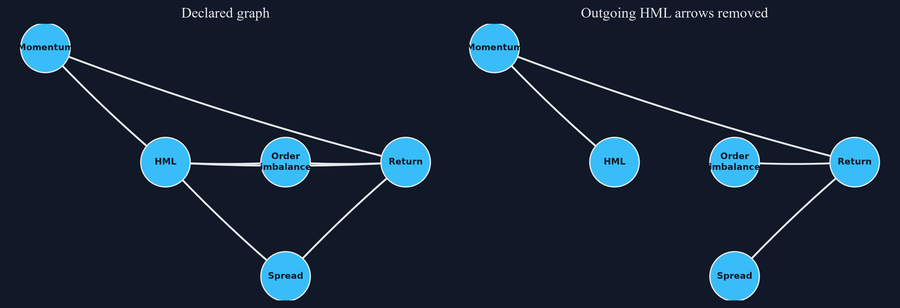

In [1]:
positions = {"Momentum": (0, 1), "HML": (1, 0), "Order imbalance": (2, 0), "Return": (3, 0), "Spread": (2, -1)}
labels = {"Momentum": "Momentum", "HML": "HML", "Order imbalance": "Order\nimbalance", "Return": "Return", "Spread": "Spread"}
figure, axes = plt.subplots(1, 2, figsize=(12, 4.2))
draw_graph(axes[0], graph, positions, "Declared graph", labels=labels)
draw_graph(axes[1], backdoor_graph, positions, "Outgoing HML arrows removed", labels=labels)
figure.tight_layout()
save_figure(figure, "backdoor_original_mutilated")
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#111827", "axes.facecolor": "#111827", "axes.edgecolor": "#94A3B8", "axes.labelcolor": "#E5E7EB", "axes.titlecolor": "#E5E7EB", "axes.titleweight": "bold", "xtick.color": "#94A3B8", "ytick.color": "#94A3B8", "text.color": "#E5E7EB", "grid.color": "#374151", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#111827", "legend.edgecolor": "#374151", "legend.framealpha": 0.96, "savefig.facecolor": "#111827", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## The Adjustment Formula

When the graphical conditions hold, the intervention distribution is obtained by averaging conditional outcome distributions over the adjustment variables:

$$
p(y\mid\operatorname{do}(x))
=\sum_s p(y\mid x,s)p(s).
$$

Here, $x$ is a fixed treatment value, $y$ is an outcome value, $s$ ranges over possible values of the valid adjustment set $S$, $p(y\mid x,s)$ is an observed conditional distribution, $p(s)$ is the marginal distribution of the adjustment variables, and $\operatorname{do}(x)$ denotes an intervention that sets treatment to $x$.

,Treatment,Observed outcome chance,Adjusted intervention chance
0,0,0.107143,0.21
1,1,0.590909,0.46


,Comparison,Effect
0,Observed difference,0.483766
1,Adjusted intervention difference,0.25
2,Known structural difference,0.25


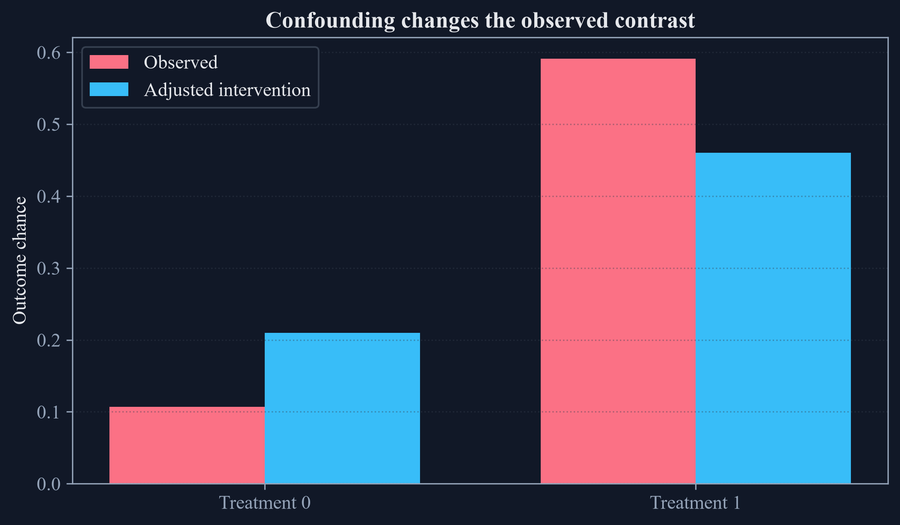

In [2]:
p_c = {0: 0.60, 1: 0.40}
p_x_given_c = {(0, 0): 0.80, (1, 0): 0.20, (0, 1): 0.20, (1, 1): 0.80}
p_y_given_xc = {(x, c): 0.05 + 0.25 * x + 0.40 * c for x in (0, 1) for c in (0, 1)}
rows = []
observational = {}
adjusted = {}
for x in (0, 1):
    p_x = sum(p_x_given_c[(x, c)] * p_c[c] for c in (0, 1))
    observational[x] = sum(p_y_given_xc[(x, c)] * p_x_given_c[(x, c)] * p_c[c] for c in (0, 1)) / p_x
    adjusted[x] = sum(p_y_given_xc[(x, c)] * p_c[c] for c in (0, 1))
    rows.append({"Treatment": x, "Observed outcome chance": observational[x], "Adjusted intervention chance": adjusted[x]})
binary_adjustment = pd.DataFrame(rows)
binary_effects = pd.DataFrame([
    {"Comparison": "Observed difference", "Effect": observational[1] - observational[0]},
    {"Comparison": "Adjusted intervention difference", "Effect": adjusted[1] - adjusted[0]},
    {"Comparison": "Known structural difference", "Effect": 0.25},
])
save_table(binary_adjustment, "backdoor_binary_adjustment", "Observed and adjusted outcome chances in a binary example.", "tab:chapter24-backdoor-binary-adjustment")
save_table(binary_effects, "backdoor_binary_effects", "Observed, adjusted, and known effects in the binary example.", "tab:chapter24-backdoor-binary-effects")
display(binary_adjustment)
display(binary_effects)

figure, axis = plt.subplots(figsize=(7.6, 4.5))
index = np.arange(2)
axis.bar(index - 0.18, [observational[0], observational[1]], width=0.36, color=palette["rose"], label="Observed")
axis.bar(index + 0.18, [adjusted[0], adjusted[1]], width=0.36, color=palette["cyan"], label="Adjusted intervention")
axis.set_xticks(index, ["Treatment 0", "Treatment 1"])
axis.set_ylabel("Outcome chance")
axis.set_title("Confounding changes the observed contrast")
axis.legend()
axis.grid(axis="y", alpha=0.4)
figure.tight_layout()
save_figure(figure, "backdoor_binary_adjustment_comparison")

## A Known Linear System

The controlled experiment is generated by a common cause, a treatment, a mediator, an outcome, and a downstream common effect:

$$
X=\delta C+\varepsilon_X,\qquad
M=aX+\varepsilon_M,\qquad
Y=dX+bM+\gamma C+\varepsilon_Y,\qquad
K=X+Y+\varepsilon_K.
$$

Here, $C$ is the observed common cause, $X$ is treatment, $M$ is the mediator, $Y$ is outcome, $K$ is the collider, $\delta$ is the common-cause loading on treatment, $a$ is the treatment-to-mediator coefficient, $d$ is the direct effect, $b$ is the mediator-to-outcome coefficient, $\gamma$ is the common-cause loading on outcome, and the four $\varepsilon$ terms are independent standard-normal shocks.

In this linear system, the total effect combines the direct path and the path through the mediator:

$$
\tau_{X\to Y}=d+ab.
$$

Here, $\tau_{X\to Y}$ is the total effect of treatment on outcome, $d$ is the direct-path coefficient, $a$ is the treatment-to-mediator coefficient, and $b$ is the mediator-to-outcome coefficient.

### Simulate backdoor

In [ ]:
def simulate_backdoor(n, delta=0.8, a=0.7, direct=0.5, b=0.6, gamma=0.9, seed=240101):
    rng = np.random.default_rng(seed)
    common = rng.standard_normal(n)
    treatment_values = delta * common + rng.standard_normal(n)
    mediator = a * treatment_values + rng.standard_normal(n)
    outcome_values = direct * treatment_values + b * mediator + gamma * common + rng.standard_normal(n)
    collider = treatment_values + outcome_values + rng.standard_normal(n)
    neutral = rng.standard_normal(n)
    return pd.DataFrame({"Treatment": treatment_values, "Common cause": common, "Mediator": mediator, "Outcome": outcome_values, "Collider": collider, "Neutral": neutral})



### Values used in the known linear back-door experiment

In [3]:
backdoor_parameters = pd.DataFrame([
    {"Parameter": "Common-cause loading on treatment", "Symbol": "delta", "Value": 0.8},
    {"Parameter": "Treatment-to-mediator coefficient", "Symbol": "a", "Value": 0.7},
    {"Parameter": "Direct effect", "Symbol": "d", "Value": 0.5},
    {"Parameter": "Mediator-to-outcome coefficient", "Symbol": "b", "Value": 0.6},
    {"Parameter": "Common-cause loading on outcome", "Symbol": "gamma", "Value": 0.9},
    {"Parameter": "Known total effect", "Symbol": "tau", "Value": 0.92},
    {"Parameter": "Observations", "Symbol": "n", "Value": 50000},
])
total_effect = 0.5 + 0.7 * 0.6
sample = simulate_backdoor(50000)
specifications = [
    ("No adjustment", []),
    ("Valid common-cause adjustment", ["Common cause"]),
    ("Common cause and mediator", ["Common cause", "Mediator"]),
    ("Common cause and collider", ["Common cause", "Collider"]),
    ("Common cause and neutral variable", ["Common cause", "Neutral"]),
]
estimate_rows = []
for name, controls in specifications:
    control_values = sample[controls].to_numpy() if controls else None
    estimate = ols_slope(sample["Outcome"], sample["Treatment"], control_values)
    estimate_rows.append({"Specification": name, "Treatment coefficient": estimate, "Target for comparison": 0.5 if "mediator" in name.lower() else total_effect, "Absolute error": abs(estimate - (0.5 if "mediator" in name.lower() else total_effect))})
control_estimates = pd.DataFrame(estimate_rows)
save_table(backdoor_parameters, "backdoor_structural_parameters", "Values used in the known linear back-door experiment.", "tab:chapter24-backdoor-parameters")
save_table(control_estimates, "backdoor_control_estimates", "Treatment coefficients under five control choices.", "tab:chapter24-backdoor-control-estimates")
display(backdoor_parameters)
display(control_estimates);



,Parameter,Symbol,Value
0,Common-cause loading on treatment,delta,0.8
1,Treatment-to-mediator coefficient,a,0.7
2,Direct effect,d,0.5
3,Mediator-to-outcome coefficient,b,0.6
4,Common-cause loading on outcome,gamma,0.9
5,Known total effect,tau,0.92
6,Observations,n,50000


,Specification,Treatment coefficient,Target for comparison,Absolute error
0,No adjustment,1.356323,0.92,0.436323
1,Valid common-cause adjustment,0.92016,0.92,0.00016
2,Common cause and mediator,0.503408,0.5,0.003408
3,Common cause and collider,-0.188271,0.92,1.108271
4,Common cause and neutral variable,0.920165,0.92,0.000165


### The control set determines the fitted target

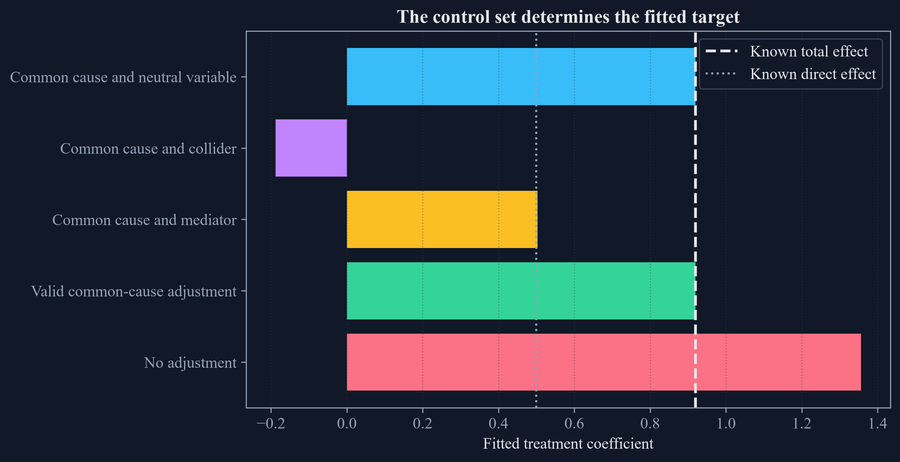

In [3]:
figure, axis = plt.subplots(figsize=(9.2, 4.8))
colors = [palette["rose"], palette["green"], palette["amber"], palette["violet"], palette["cyan"]]
axis.barh(control_estimates["Specification"], control_estimates["Treatment coefficient"], color=colors)
axis.axvline(total_effect, color=palette["text"], linewidth=2, linestyle="--", label="Known total effect")
axis.axvline(0.5, color=palette["muted"], linewidth=1.5, linestyle=":", label="Known direct effect")
axis.set_xlabel("Fitted treatment coefficient")
axis.set_title("The control set determines the fitted target")
axis.legend()
axis.grid(axis="x", alpha=0.4)
figure.tight_layout()
save_figure(figure, "backdoor_control_coefficients")

### Studying recovery across sample and confounding regimes

The bias and root mean squared error across repeated samples are calculated as follows:

$$
\widehat{\operatorname{Bias}}=\frac{1}{R}\sum_{r=1}^{R}(\widehat\tau_r-\tau),
\qquad
\widehat{\operatorname{RMSE}}=\sqrt{\frac{1}{R}\sum_{r=1}^{R}(\widehat\tau_r-\tau)^2}.
$$

Here, $R$ is the number of repeated samples, $r$ labels one sample, $\widehat\tau_r$ is its fitted treatment coefficient, $\tau$ is the known total effect, $\widehat{\operatorname{Bias}}$ is the average signed error, and $\widehat{\operatorname{RMSE}}$ is the square root of the average squared error.

#### Treatment coefficients as sample size increases

In [4]:
size_rows = []
for n in (250, 500, 1000, 2500, 5000, 10000, 50000):
    data = simulate_backdoor(n, seed=240100 + n)
    size_rows.append({"Observations": n, "Unadjusted coefficient": ols_slope(data["Outcome"], data["Treatment"]), "Adjusted coefficient": ols_slope(data["Outcome"], data["Treatment"], data[["Common cause"]]), "Known total effect": total_effect})
sample_size_convergence = pd.DataFrame(size_rows)
save_table(sample_size_convergence, "backdoor_sample_size_convergence", "Treatment coefficients as sample size increases.", "tab:chapter24-backdoor-sample-size")
display(sample_size_convergence);



,Observations,Unadjusted coefficient,Adjusted coefficient,Known total effect
0,250,1.26701,0.856293,0.92
1,500,1.345595,0.878318,0.92
2,1000,1.413758,1.011052,0.92
3,2500,1.38296,0.910876,0.92
4,5000,1.364683,0.933709,0.92
5,10000,1.348511,0.916526,0.92
6,50000,1.362643,0.93094,0.92


#### More observations do not remove omitted-common-cause bias

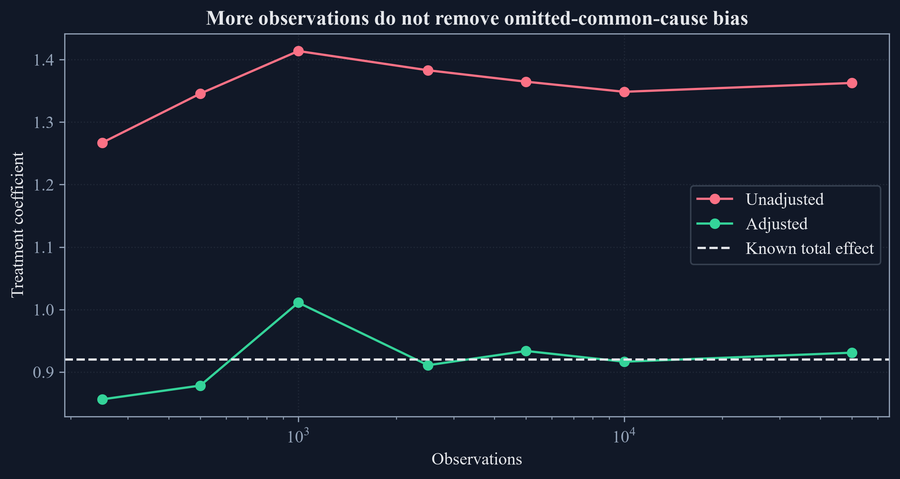

,Common-cause loading,Method,Mean coefficient,Bias,Root mean squared error,Repetitions
0,0,Unadjusted,0.927199,0.007199,0.041683,150
1,0,Adjusted,0.926669,0.006669,0.03256,150
2,0.4,Unadjusted,1.236959,0.316959,0.319096,150
3,0.4,Adjusted,0.923325,0.003325,0.030533,150
4,0.8,Unadjusted,1.358836,0.438836,0.439709,150
5,0.8,Adjusted,0.918799,-0.001201,0.032142,150
6,1.2,Unadjusted,1.36128,0.44128,0.441886,150
7,1.2,Adjusted,0.922118,0.002118,0.032805,150


In [4]:
figure, axis = plt.subplots(figsize=(8.5, 4.6))
axis.plot(sample_size_convergence["Observations"], sample_size_convergence["Unadjusted coefficient"], marker="o", color=palette["rose"], label="Unadjusted")
axis.plot(sample_size_convergence["Observations"], sample_size_convergence["Adjusted coefficient"], marker="o", color=palette["green"], label="Adjusted")
axis.axhline(total_effect, color=palette["text"], linestyle="--", label="Known total effect")
axis.set_xscale("log")
axis.set_xlabel("Observations")
axis.set_ylabel("Treatment coefficient")
axis.set_title("More observations do not remove omitted-common-cause bias")
axis.legend()
axis.grid(alpha=0.4)
figure.tight_layout()
save_figure(figure, "backdoor_sample_size_convergence")

sweep_rows = []
repetitions = 150
for delta in (0.0, 0.4, 0.8, 1.2):
    naive_values = []
    adjusted_values = []
    for repetition in range(repetitions):
        data = simulate_backdoor(1500, delta=delta, seed=240200 + repetition + int(delta * 1000))
        naive_values.append(ols_slope(data["Outcome"], data["Treatment"]))
        adjusted_values.append(ols_slope(data["Outcome"], data["Treatment"], data[["Common cause"]]))
    for method, values in (("Unadjusted", naive_values), ("Adjusted", adjusted_values)):
        sweep_rows.append({"Common-cause loading": delta, "Method": method, "Mean coefficient": np.mean(values), "Bias": np.mean(values) - total_effect, "Root mean squared error": np.sqrt(mean_squared_error(values, total_effect)), "Repetitions": repetitions})
confounding_sweep = pd.DataFrame(sweep_rows)
save_table(confounding_sweep, "backdoor_confounding_sweep", "Repeated-sample error as common-cause strength increases.", "tab:chapter24-backdoor-confounding-sweep")
display(confounding_sweep);



#### Average signed error

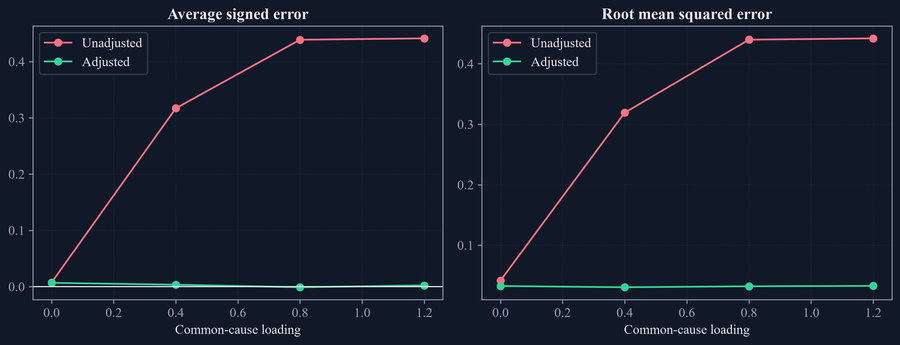

In [4]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for method, color in (("Unadjusted", palette["rose"]), ("Adjusted", palette["green"])):
    subset = confounding_sweep[confounding_sweep["Method"] == method]
    axes[0].plot(subset["Common-cause loading"], subset["Bias"], marker="o", color=color, label=method)
    axes[1].plot(subset["Common-cause loading"], subset["Root mean squared error"], marker="o", color=color, label=method)
axes[0].axhline(0, color=palette["text"], linewidth=1)
axes[0].set_title("Average signed error")
axes[1].set_title("Root mean squared error")
for axis in axes:
    axis.set_xlabel("Common-cause loading")
    axis.grid(alpha=0.4)
    axis.legend()
figure.tight_layout()
save_figure(figure, "backdoor_confounding_sweep")

## Checking the method contract at its limits

A fitted adjustment estimate is interpreted relative to the target and graph that were fixed before fitting:

$$
\widehat\tau_S\rightsquigarrow\tau
\quad\text{only if}\quad
S\text{ satisfies the stated identification conditions and the fitted model is suitable}.
$$

Here, $\widehat\tau_S$ is the estimate obtained after adjusting for $S$, $\tau$ is the intended causal quantity, the arrow denotes convergence under repeated sampling, and the qualification records that a selected control set alone does not prove the graph or correct a poor outcome model.

In [5]:
cyclic_graph = nx.DiGraph([("A", "B"), ("B", "A")])
input_checks = pd.DataFrame([
    contract_result("Cyclic graph", lambda: backdoor_adjustment_set(cyclic_graph, "A", "B"), "ValueError"),
    contract_result("Missing treatment", lambda: backdoor_adjustment_set(graph, "Missing", "Return"), "ValueError"),
    contract_result("Undirected graph", lambda: backdoor_adjustment_set(nx.Graph(graph), "HML", "Return"), "TypeError"),
])
backdoor_summary = pd.DataFrame([
    {"Question": "Which observed set blocks the back-door path?", "Answer": ", ".join(sorted(adjustment_set))},
    {"Question": "Does the mediator belong in a total-effect adjustment set?", "Answer": "No"},
    {"Question": "Does the collider belong in the adjustment set?", "Answer": "No"},
    {"Question": "Does a larger sample repair omitted-common-cause bias?", "Answer": "No"},
    {"Question": "Can the graph be proved by the fitted coefficient?", "Answer": "No"},
])
save_table(input_checks, "backdoor_input_checks", "Input checks for the released back-door calculations.", "tab:chapter24-backdoor-input-checks")
save_table(backdoor_summary, "backdoor_section_summary", "Main conclusions from the back-door experiments.", "tab:chapter24-backdoor-summary")
display(input_checks)
display(backdoor_summary)

,Check,Expected result,Observed result,Passed
0,Cyclic graph,Rejected,Rejected,True
1,Missing treatment,Rejected,Rejected,True
2,Undirected graph,Rejected,Rejected,True


,Question,Answer
0,Which observed set blocks the back-door path?,Momentum
1,Does the mediator belong in a total-effect adj...,No
2,Does the collider belong in the adjustment set?,No
3,Does a larger sample repair omitted-common-cau...,No
4,Can the graph be proved by the fitted coeffici...,No


## Tests

In [6]:
assert adjustment_set == {"Momentum"}
assert decisions == {"Momentum": "valid_confounder", "Order imbalance": "avoid_mediator", "Spread": "avoid_collider"}
assert criterion_checks["Result"].all()
assert np.isclose(binary_effects.loc[binary_effects["Comparison"] == "Adjusted intervention difference", "Effect"].iloc[0], 0.25)
assert abs(control_estimates.loc[control_estimates["Specification"] == "Valid common-cause adjustment", "Treatment coefficient"].iloc[0] - total_effect) < 0.02
assert abs(control_estimates.loc[control_estimates["Specification"] == "Common cause and mediator", "Treatment coefficient"].iloc[0] - 0.5) < 0.02
assert abs(sample_size_convergence.iloc[-1]["Adjusted coefficient"] - total_effect) < 0.02
assert confounding_sweep.query("Method == 'Adjusted'")["Root mean squared error"].max() < confounding_sweep.query("Method == 'Unadjusted'")["Root mean squared error"].max()
assert input_checks["Passed"].all()
for stem in ["backdoor_original_mutilated", "backdoor_binary_adjustment_comparison", "backdoor_control_coefficients", "backdoor_sample_size_convergence", "backdoor_confounding_sweep"]:
    assert (FIGURES / f"{stem}.pdf").is_file()
for stem in ["backdoor_graph_edges", "backdoor_adjustment_decisions", "backdoor_criterion_checks", "backdoor_binary_adjustment", "backdoor_binary_effects", "backdoor_structural_parameters", "backdoor_control_estimates", "backdoor_sample_size_convergence", "backdoor_confounding_sweep", "backdoor_input_checks", "backdoor_section_summary"]:
    assert (TABLES / f"{stem}.tex").is_file()